# LKS AI — Prediksi Tingkat Stres Mahasiswa (Linear Regression dari nol)

| Modul | Isi |
|---|---|
| A | Data Preparation & EDA |
| B | Pemodelan Linear Regression (OOP: `Preprocessor`, `LinearRegression`, `StressModel`) |
| C | Evaluasi + confusion matrix |
| D | Uji coba data baru + GUI (`gui_stres_lr.py`) |

Library: numpy, pandas, matplotlib, seaborn (tanpa scikit-learn).

# MODUL A — Data Preparation & EDA

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
TARGET = 'Stress_Level'
NUM = ['Age', 'CGPA', 'Sleep_Duration', 'Study_Hours', 'Social_Media_Hours', 'Physical_Activity']

df_raw = pd.read_csv('Student_lifestyle_data.csv')
print(df_raw.shape)
df_raw.head()

(100000, 10)


,Student_ID,Age,Gender,Department,CGPA,Sleep_Duration,Study_Hours,Social_Media_Hours,Physical_Activity,Stress_Level
0,1001,22.0,Female,Science,NaN,7.3,3.3,3.4,114.0,5.0
1,1002,20.0,Male,Engineering,2.72,5.5,7.2,6.0,NaN,2.0
2,1003,20.0,Male,Medical,NaN,5.4,2.3,1.8,137.0,3.0
3,1004,21.0,Male,Engineering,3.63,8.1,2.0,4.6,130.0,3.0
4,1005,19.0,Male,Arts,3.14,6.8,2.6,4.3,4.0,6.0


**Fitur:** Age, Gender, Department, CGPA, Sleep_Duration, Study_Hours, Social_Media_Hours, Physical_Activity.
**Label:** `Stress_Level` (angka 0–10).

Catatan: kolom **Depression** di slide **tidak ada** di CSV, jadi label yang diprediksi adalah Stress_Level. Karena labelnya angka, cocok untuk **Linear Regression**. Untuk confusion matrix, prediksinya diubah jadi kategori: **Rendah (≤ 3), Sedang (4–5), Tinggi (≥ 6)**.

In [2]:
df_raw.info()
print('\nDuplikat:', df_raw.duplicated().sum())
df_raw.describe().round(2)

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 10 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   Student_ID          100000 non-null  int64  
 1   Age                 98000 non-null   float64
 2   Gender              98000 non-null   str    
 3   Department          98000 non-null   str    
 4   CGPA                98000 non-null   float64
 5   Sleep_Duration      98000 non-null   float64
 6   Study_Hours         98000 non-null   float64
 7   Social_Media_Hours  98000 non-null   float64
 8   Physical_Activity   98000 non-null   float64
 9   Stress_Level        98000 non-null   float64
dtypes: float64(7), int64(1), str(2)
memory usage: 7.6 MB

Duplikat: 0


,Student_ID,Age,CGPA,Sleep_Duration,Study_Hours,Social_Media_Hours,Physical_Activity,Stress_Level
count,100000.00,98000.00,98000.00,98000.00,98000.00,98000.00,98000.00,98000.00
mean,51000.50,21.01,2.90,6.99,4.51,3.50,74.35,4.13
std,28867.66,2.00,0.53,1.50,1.98,1.49,43.36,1.42
min,1001.00,18.00,1.56,3.00,0.00,0.00,0.00,2.00
25%,26000.75,19.00,2.45,6.00,3.20,2.50,37.00,3.00
50%,51000.50,21.00,2.90,7.00,4.50,3.50,74.00,4.00
75%,76000.25,23.00,3.35,8.00,5.80,4.50,112.00,5.00
max,101000.00,24.00,4.00,12.00,12.80,10.00,149.00,10.00


## A.1 Missing value

In [3]:
print(df_raw.isna().sum())
print('\nBaris dengan minimal 1 nilai kosong:', df_raw.isna().any(axis=1).sum())

Student_ID               0
Age                   2000
Gender                2000
Department            2000
CGPA                  2000
Sleep_Duration        2000
Study_Hours           2000
Social_Media_Hours    2000
Physical_Activity     2000
Stress_Level          2000
dtype: int64

Baris dengan minimal 1 nilai kosong: 16631


- Setiap kolom kosong **2%**, tersebar di **16,6% baris**. Kalau semua baris tidak lengkap dibuang, terlalu banyak data yang hilang.
- **Label kosong → dibuang** (2.000 baris), karena tidak bisa dipakai belajar.
- **Fitur kosong → diisi median/modus di Modul B**, memakai nilai dari data latih saja supaya tidak bocor.
- Tidak ada duplikat, dan semua nilai masuk rentang wajar.

In [4]:
df = df_raw.drop(columns='Student_ID').dropna(subset=[TARGET]).reset_index(drop=True)
df.to_csv('df_clean.csv', index=False)
df.shape

(98000, 9)

## A.2 EDA

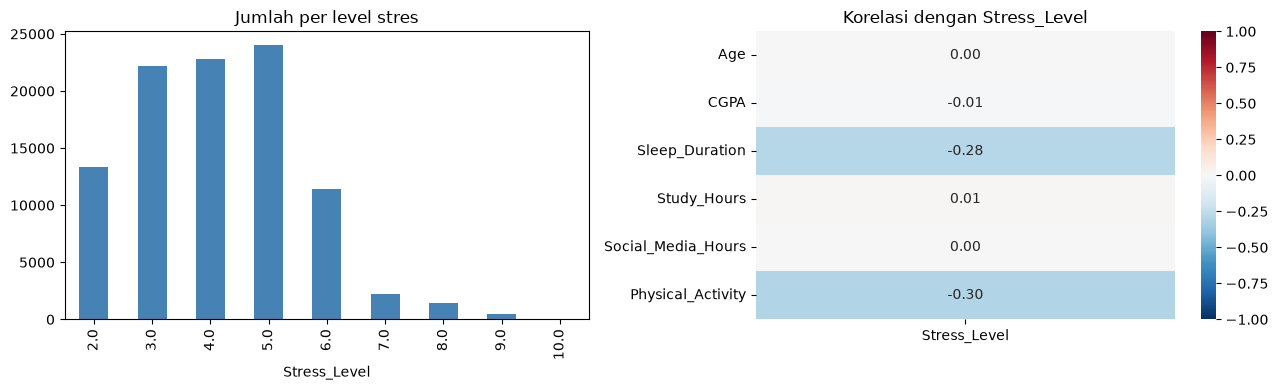

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
df[TARGET].value_counts().sort_index().plot.bar(ax=ax[0], color='steelblue', title='Jumlah per level stres')
sns.heatmap(df[NUM + [TARGET]].corr()[[TARGET]].drop(TARGET), annot=True, fmt='.2f', cmap='RdBu_r', vmin=-1, vmax=1, ax=ax[1])
ax[1].set_title('Korelasi dengan Stress_Level')
plt.tight_layout(); plt.show()

Stres terbanyak di level 3–5. Hanya **Sleep_Duration (−0,28)** dan **Physical_Activity (−0,30)** yang berkorelasi dengan stres. Fitur lain hampir 0.

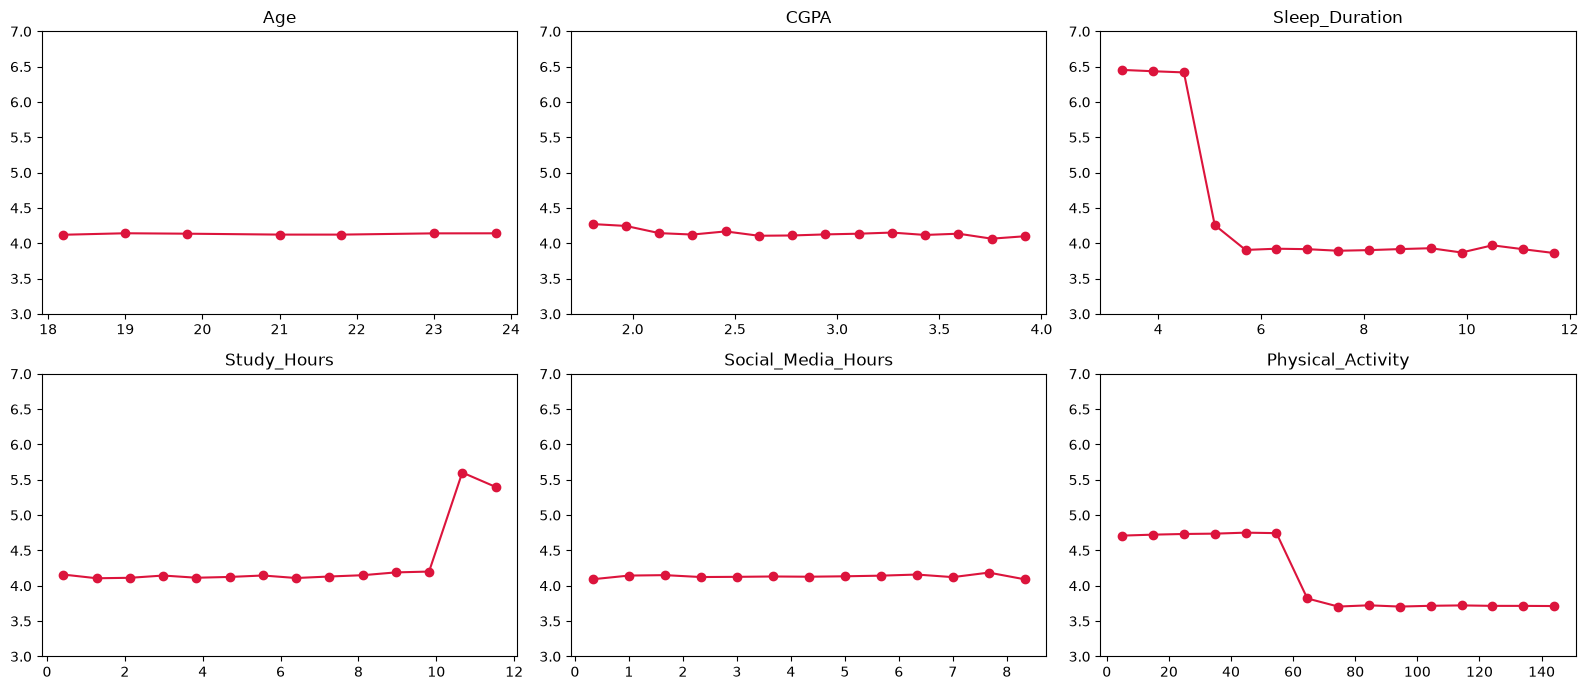

{'Female': 4.13, 'Male': 4.13}
{'Arts': 4.13, 'Business': 4.13, 'Engineering': 4.13, 'Medical': 4.12, 'Science': 4.15}


In [6]:
# Rata-rata stres per kelompok nilai: melihat BENTUK hubungannya
fig, ax = plt.subplots(2, 3, figsize=(16, 7))
for a, c in zip(ax.ravel(), NUM):
    g = df.groupby(pd.cut(df[c], 15), observed=True)[TARGET].agg(['mean', 'count'])
    g = g[g['count'] >= 30]
    a.plot([i.mid for i in g.index], g['mean'], marker='o', color='crimson')
    a.set_title(c); a.set_ylim(3, 7)
plt.tight_layout(); plt.show()

print(df.groupby('Gender')[TARGET].mean().round(2).to_dict())
print(df.groupby('Department')[TARGET].mean().round(2).to_dict())

**Hubungannya berbentuk tangga, bukan garis miring:**
- Tidur **di bawah 5 jam** → stres melonjak.
- Aktivitas fisik **60 menit ke bawah** → stres naik.
- Belajar **lebih dari 10 jam** → stres naik.
- Usia, IPK, medsos, gender, jurusan: **datar**, tidak berpengaruh.

In [7]:
# Cari titik lompatan yang tepat
for c, lo, hi in [('Sleep_Duration', 4.7, 5.2), ('Physical_Activity', 58, 63), ('Study_Hours', 9.8, 10.3)]:
    s = df[df[c].between(lo, hi)]
    print(c, s.groupby(s[c].round(1))[TARGET].mean().round(2).to_dict())

Sleep_Duration {4.7: 6.36, 4.8: 6.46, 4.9: 6.41, 5.0: 3.98, 5.1: 3.97, 5.2: 3.87}
Physical_Activity {58.0: 4.73, 59.0: 4.73, 60.0: 4.71, 61.0: 3.76, 62.0: 3.71, 63.0: 3.72}
Study_Hours {9.8: 3.98, 9.9: 4.45, 10.0: 4.0, 10.1: 5.66, 10.2: 5.71, 10.3: 6.11}


**Kesimpulan EDA:** titik lompatannya tepat di **tidur 5 jam**, **aktivitas 60 menit**, dan **belajar 10 jam**. Ketiga batas ini dijadikan **fitur 0/1** di Modul B.

# MODUL B — Pemodelan Linear Regression
## B.1 Split 70 / 15 / 15
Latih 70% (belajar), validasi 15% (memilih model dan batas kategori), uji 15% (nilai akhir, dibuka sekali). Stratified per level stres.

In [8]:
def split_stratified(y, fracs, seed):
    rng = np.random.default_rng(seed)
    bagian = [[] for _ in fracs]
    for kelas in np.unique(y):
        idx = rng.permutation(np.where(y == kelas)[0])
        batas = np.round(np.cumsum(fracs)[:-1] * len(idx)).astype(int)
        for i, potong in enumerate(np.split(idx, batas)):
            bagian[i].extend(potong)
    return [np.sort(b) for b in bagian]

i_tr, i_va, i_te = split_stratified(df[TARGET].values, (0.70, 0.15, 0.15), SEED)
train, val, test = df.iloc[i_tr], df.iloc[i_va], df.iloc[i_te]
y_tr, y_va, y_te = train[TARGET].values, val[TARGET].values, test[TARGET].values
print('latih', len(train), '| validasi', len(val), '| uji', len(test))

latih 68601 | validasi 14699 | uji 14700


## B.2 Preprocessing dan rumus

**Preprocessing** (semua dihitung dari data latih):
- Isi kosong: **median** (angka), **modus** (kategori).
- **Fitur ambang** (hasil EDA), nilainya 0/1: `Tidur_Kurang` (tidur < 5), `Aktivitas_Rendah` (aktivitas ≤ 60), `Belajar_Berlebih` (belajar > 10).
- Untuk versi pembanding (fitur asli): one-hot Gender & Department.
- **Z-score** semua fitur, supaya satu learning rate cocok untuk semua fitur.

**Linear Regression:**
1. Prediksi: **ŷ = X·w + b**
2. Loss MSE: **(1/n) Σ (ŷ − y)²**
3. Gradien: **∂/∂w = (2/n) Xᵀ(ŷ − y)**, **∂/∂b = (2/n) Σ(ŷ − y)**
4. Update: **w ← w − lr · gradien**, diulang sebanyak `epochs`.

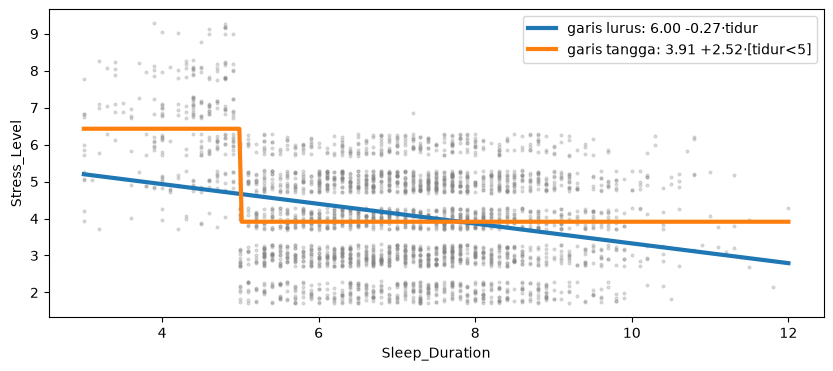

In [9]:
# Visual: Linear Regression 1 fitur, garis lurus vs garis tangga
s = train[['Sleep_Duration', TARGET]].dropna()
x, y = s['Sleep_Duration'].values, s[TARGET].values
b1, w1 = np.polyfit(x, y, 1)[::-1]                     # garis lurus: y = b1 + w1*tidur
b2, w2 = np.polyfit((x < 5).astype(float), y, 1)[::-1]  # garis tangga: y = b2 + w2*[tidur<5]

grid = np.linspace(3, 12, 300)
idx = np.random.default_rng(SEED).choice(len(x), 3000, replace=False)
plt.figure(figsize=(10, 4))
plt.scatter(x[idx], y[idx] + np.random.default_rng(1).uniform(-0.3, 0.3, 3000), s=4, alpha=0.25, color='gray')
plt.plot(grid, b1 + w1 * grid, lw=3, label=f'garis lurus: {b1:.2f} {w1:+.2f}·tidur')
plt.plot(grid, b2 + w2 * (grid < 5), lw=3, label=f'garis tangga: {b2:.2f} {w2:+.2f}·[tidur<5]')
plt.xlabel('Sleep_Duration'); plt.ylabel(TARGET); plt.legend(); plt.show()

**Garis lurus** tidak cocok dengan data yang berbentuk tangga. **Garis tangga** jauh lebih pas. Keduanya **tetap Linear Regression**; bedanya hanya fitur yang dimasukkan.

## B.3 Class model (OOP)
`%%writefile` menyimpan sel ini sebagai **`model_linreg.py`**, yang juga dipakai GUI. Kalau class diubah, jalankan ulang sel ini **dan** sel `%run` di bawahnya.

In [10]:
%%writefile model_linreg.py
import json
import numpy as np
import pandas as pd


class Preprocessor:
    NUM = ['Age', 'CGPA', 'Sleep_Duration', 'Study_Hours', 'Social_Media_Hours', 'Physical_Activity']
    KAT = ['Gender', 'Department']

    def __init__(self, ambang=True):
        self.ambang = ambang          # True = 3 fitur ambang hasil EDA, False = fitur asli

    def fit(self, data):
        """Pelajari semua parameter dari data LATIH."""
        self.median = {c: float(data[c].median()) for c in self.NUM}
        self.modus = {c: str(data[c].mode()[0]) for c in self.KAT}
        self.onehot = {c: sorted(str(k) for k in data[c].dropna().unique() if k != self.modus[c]) for c in self.KAT}
        X = self.fitur_mentah(data)
        self.kolom = list(X.columns)
        self.mean = X.mean().to_dict()
        self.std = X.std().to_dict()
        return self

    def fitur_mentah(self, data):
        """Isi kosong lalu buat fitur (belum di-z-score). data bisa DataFrame atau dict (dari GUI)."""
        if isinstance(data, dict):
            data = pd.DataFrame([data])
        d = data.copy()
        for c in self.NUM:
            d[c] = pd.to_numeric(d[c], errors='coerce').fillna(self.median[c])
        for c in self.KAT:
            d[c] = d[c].fillna(self.modus[c])
        X = pd.DataFrame(index=d.index)
        if self.ambang:
            X['Tidur_Kurang'] = d['Sleep_Duration'] < 5
            X['Aktivitas_Rendah'] = d['Physical_Activity'] <= 60
            X['Belajar_Berlebih'] = d['Study_Hours'] > 10
        else:
            for c in self.NUM:
                X[c] = d[c]
            for c, kelas in self.onehot.items():
                for k in kelas:
                    X[f'{c}_{k}'] = d[c] == k
        return X.astype(float)

    def transform(self, data):
        """Fitur + z-score memakai mean/std data latih."""
        X = self.fitur_mentah(data)[self.kolom]
        return (X - pd.Series(self.mean)) / pd.Series(self.std)


class LinearRegression:
    def __init__(self, lr=0.1, epochs=500):
        self.lr = lr
        self.epochs = epochs

    def predict(self, X):
        return X @ self.w + self.b

    def loss(self, X, y):
        return np.mean((self.predict(X) - y) ** 2)            # MSE

    def fit(self, X, y):
        """Gradient descent."""
        self.w, self.b = np.zeros(X.shape[1]), 0.0
        self.riwayat = []
        for _ in range(self.epochs):
            self.riwayat.append(self.loss(X, y))
            err = self.predict(X) - y
            self.w -= self.lr * 2 * X.T @ err / len(y)          # dMSE/dw
            self.b -= self.lr * 2 * err.mean()                  # dMSE/db
        return self

    def fit_normal(self, X, y):
        """Jawaban pasti (Normal Equation), untuk mengecek gradient descent."""
        X1 = np.column_stack([np.ones(len(X)), X])
        theta = np.linalg.solve(X1.T @ X1, X1.T @ y)
        self.b, self.w = theta[0], theta[1:]
        return self


class StressModel:
    KATEGORI = np.array(['Rendah', 'Sedang', 'Tinggi'])

    def __init__(self, prep, model, batas=(3.5, 5.5)):
        self.prep, self.model, self.batas = prep, model, list(batas)

    @staticmethod
    def ke_kategori(nilai, batas=(3.5, 5.5)):
        return StressModel.KATEGORI[np.digitize(nilai, batas)]

    def skor(self, data):
        """Prediksi level stres 0-10."""
        return np.clip(self.model.predict(self.prep.transform(data).values), 0, 10)

    def prediksi(self, data):
        s = self.skor(data)
        return s, self.ke_kategori(s, self.batas)

    def koefisien(self):
        """Bobot dalam satuan asli: efek = w / std, intercept = b - sum(efek * mean)."""
        efek = pd.Series(self.model.w, index=self.prep.kolom) / pd.Series(self.prep.std)[self.prep.kolom]
        intercept = self.model.b - (efek * pd.Series(self.prep.mean)[self.prep.kolom]).sum()
        return float(intercept), efek

    def save(self, path):
        p = self.prep
        isi = {'ambang': p.ambang, 'median': p.median, 'modus': p.modus, 'onehot': p.onehot, 'kolom': p.kolom,
               'mean': p.mean, 'std': p.std, 'w': self.model.w.tolist(), 'b': float(self.model.b), 'batas': self.batas}
        with open(path, 'w') as f:
            json.dump(isi, f, indent=1)

    @classmethod
    def load(cls, path):
        with open(path) as f:
            isi = json.load(f)
        prep = Preprocessor(isi['ambang'])
        for k in ['median', 'modus', 'onehot', 'kolom', 'mean', 'std']:
            setattr(prep, k, isi[k])
        model = LinearRegression()
        model.w, model.b = np.array(isi['w']), isi['b']
        return cls(prep, model, isi['batas'])

Overwriting model_linreg.py


In [11]:
%run model_linreg.py

## B.4 Training: fitur asli vs fitur ambang

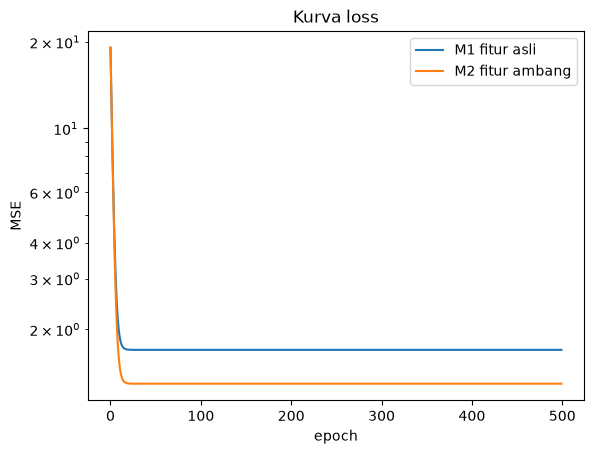

M1 fitur asli: selisih bobot GD vs Normal Equation = 2.6e-15
M2 fitur ambang: selisih bobot GD vs Normal Equation = 4.0e-15


In [ ]:
hasil = {}
for nama, ambang in [('M1 fitur asli', False), ('M2 fitur ambang', True)]:
    prep = Preprocessor(ambang=ambang).fit(train)
    model = LinearRegression(lr=0.1, epochs=500).fit(prep.transform(train).values, y_tr)
    hasil[nama] = StressModel(prep, model)
    plt.plot(model.riwayat, label=nama)
plt.yscale('log'); plt.xlabel('epoch'); plt.ylabel('MSE'); plt.legend(); plt.title('Kurva loss'); plt.show()

# Bukti training benar: hasil gradient descent harus sama dengan Normal Equation
for nama, sm in hasil.items():
    pasti = LinearRegression().fit_normal(sm.prep.transform(train).values, y_tr)
    print(f'{nama}: selisih bobot GD vs Normal Equation = {np.abs(sm.model.w - pasti.w).max():.1e}')

## B.5 Pilih model dengan data validasi

In [13]:
def metrik(y, p):
    return {'R2': 1 - np.sum((y - p) ** 2) / np.sum((y - y.mean()) ** 2),
            'MAE': np.mean(np.abs(y - p)),
            'RMSE': np.sqrt(np.mean((y - p) ** 2))}

pd.DataFrame({nama: metrik(y_va, sm.skor(val)) for nama, sm in hasil.items()}).T.round(3)

,R2,MAE,RMSE
M1 fitur asli,0.166,1.090,1.301
M2 fitur ambang,0.362,1.007,1.138


stres = 3.51 +2.51·[Tidur_Kurang] +1.00·[Aktivitas_Rendah] +1.35·[Belajar_Berlebih]


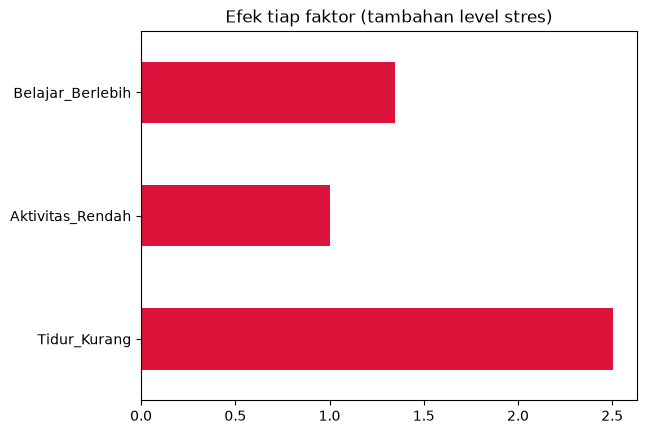

In [14]:
stress_model = hasil['M2 fitur ambang']
intercept, efek = stress_model.koefisien()
print(f'stres = {intercept:.2f} ' + ' '.join(f'{v:+.2f}·[{k}]' for k, v in efek.items()))
efek.plot.barh(color='crimson', title='Efek tiap faktor (tambahan level stres)'); plt.show()

- Fitur ambang membuat **R² naik dari 0,17 ke 0,36**. Jadi **M2 dipilih**.
- Gradient descent memberi hasil **sama** dengan Normal Equation (selisih 10⁻¹⁵). Artinya training sudah benar.
- **Cara membaca rumus:** stres dasar 3,5. **Kurang tidur +2,5** (faktor terkuat), belajar berlebih +1,35, aktivitas rendah +1.

# MODUL C — Evaluasi Model (data uji)
## C.1 Metrik regresi
Pembanding: tebak semua mahasiswa dengan rata-rata stres data latih.

In [15]:
pred_te = stress_model.skor(test)
pd.DataFrame({'Baseline (rata-rata)': metrik(y_te, np.full(len(y_te), y_tr.mean())),
              'M1 fitur asli': metrik(y_te, hasil['M1 fitur asli'].skor(test)),
              'M2 fitur ambang': metrik(y_te, pred_te)}).T.round(3)

,R2,MAE,RMSE
Baseline (rata-rata),-0.000,1.154,1.425
M1 fitur asli,0.161,1.093,1.305
M2 fitur ambang,0.364,1.006,1.136


## C.2 Confusion matrix

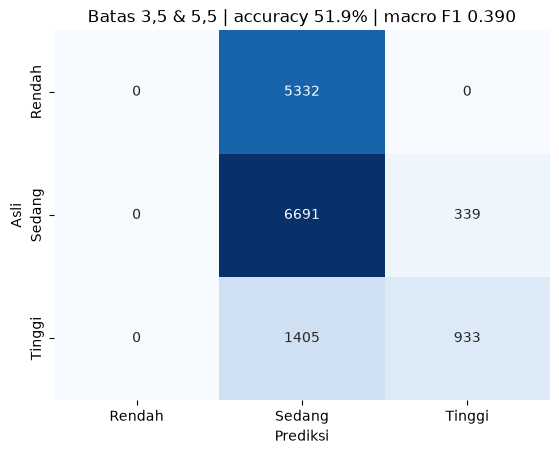

        precision  recall     f1
Rendah      0.000   0.000  0.000
Sedang      0.498   0.952  0.654
Tinggi      0.733   0.399  0.517


In [16]:
LABEL = list(StressModel.KATEGORI)
kat_asli = StressModel.ke_kategori(y_te)

def confusion_matrix(asli, pred):
    cm = pd.DataFrame(0, index=LABEL, columns=LABEL)
    for a in LABEL:
        for p in LABEL:
            cm.loc[a, p] = np.sum((asli == a) & (pred == p))
    return cm

def evaluasi_kategori(asli, pred, judul):
    cm = confusion_matrix(asli, pred)
    tp = np.diag(cm.values)
    precision = tp / np.maximum(cm.sum(axis=0).values, 1)
    recall = tp / cm.sum(axis=1).values
    f1 = np.where(precision + recall > 0, 2 * precision * recall / np.maximum(precision + recall, 1e-12), 0)
    acc = tp.sum() / cm.values.sum()
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
    plt.title(f'{judul} | accuracy {acc:.1%} | macro F1 {f1.mean():.3f}'); plt.ylabel('Asli'); plt.xlabel('Prediksi'); plt.show()
    print(pd.DataFrame({'precision': precision, 'recall': recall, 'f1': f1}, index=LABEL).round(3))
    return f1.mean()

f1_awal = evaluasi_kategori(kat_asli, StressModel.ke_kategori(pred_te, (3.5, 5.5)), 'Batas 3,5 & 5,5')

**Masalah:** kategori **Rendah tidak pernah ditebak** (recall 0). Penyebabnya, mahasiswa tanpa faktor risiko diprediksi **3,51**, sedikit di atas batas 3,5, sehingga semuanya masuk Sedang.

## C.3 Penyesuaian: geser batas kategori
Batas dicari di data **validasi** (bukan uji), memilih **macro F1** tertinggi.

In [17]:
pred_va = stress_model.skor(val)
kat_va = StressModel.ke_kategori(y_va)
print('Nilai prediksi yang mungkin:', np.unique(pred_va.round(2)))

def macro_f1(asli, pred):
    f1 = []
    for k in LABEL:
        tp = np.sum((asli == k) & (pred == k))
        p, r = tp / max(np.sum(pred == k), 1), tp / np.sum(asli == k)
        f1.append(2 * p * r / (p + r) if p + r else 0)
    return np.mean(f1)

kandidat = [(a, b) for a in np.arange(3.5, 5.0, 0.25) for b in np.arange(a + 0.5, 6.5, 0.25)]
skor_batas = {k: macro_f1(kat_va, StressModel.ke_kategori(pred_va, k)) for k in kandidat}
terbaik = max(skor_batas, key=skor_batas.get)
stress_model.batas = [float(terbaik[0]), float(terbaik[1])]
print(f'Batas 3,5 & 5,5 -> macro F1 validasi {skor_batas[(3.5, 5.5)]:.3f}')
print(f'Batas terbaik {stress_model.batas} -> macro F1 validasi {skor_batas[terbaik]:.3f}')

Nilai prediksi yang mungkin: [3.51 4.52 4.86 5.86 6.02 7.02 7.37 8.37]
Batas 3,5 & 5,5 -> macro F1 validasi 0.390
Batas terbaik [3.75, 4.75] -> macro F1 validasi 0.516


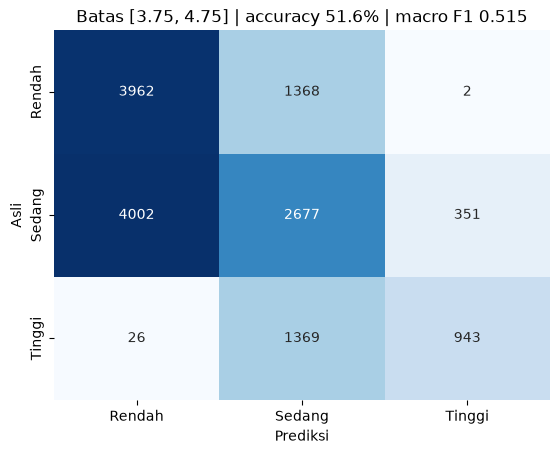

        precision  recall     f1
Rendah      0.496   0.743  0.595
Sedang      0.494   0.381  0.430
Tinggi      0.728   0.403  0.519


In [18]:
f1_baru = evaluasi_kategori(kat_asli, StressModel.ke_kategori(pred_te, stress_model.batas), f'Batas {stress_model.batas}')

Setelah batas digeser ke **3,75 & 4,75**:
- Recall Rendah naik **0% → 74%**, dan macro F1 naik **0,39 → 0,51**.
- Accuracy tetap ±52%. Sekarang ketiga kategori bisa ditebak.

## C.4 Kenapa akurasinya tidak bisa lebih tinggi?

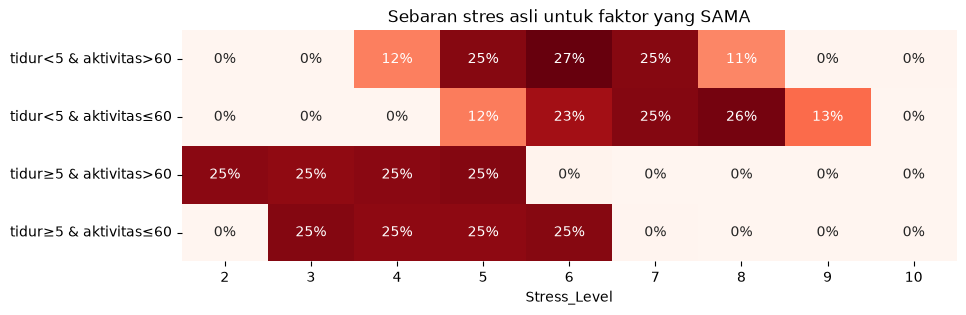

In [19]:
f = stress_model.prep.fitur_mentah(test)
kelompok = np.where(f['Tidur_Kurang'] == 1, 'tidur<5', 'tidur≥5') + ' & ' + np.where(f['Aktivitas_Rendah'] == 1, 'aktivitas≤60', 'aktivitas>60')
plt.figure(figsize=(10, 3))
sns.heatmap(pd.crosstab(kelompok, y_te.astype(int), normalize='index'), annot=True, fmt='.0%', cmap='Reds', cbar=False)
plt.title('Sebaran stres asli untuk faktor yang SAMA'); plt.xlabel(TARGET); plt.ylabel(''); plt.show()

Mahasiswa **tanpa faktor risiko** punya stres 2, 3, 4, atau 5 dengan peluang **sama (25% masing-masing)**. Input sama, jawaban acak. Jadi model apa pun **tidak bisa** menebak lebih tepat. Accuracy ±52% ini sudah **batas maksimum** data ini, bukan karena modelnya lemah.

In [20]:
stress_model.save('model_stres_lr.json')
print('Model tersimpan, batas:', stress_model.batas)

Model tersimpan, batas: [3.75, 4.75]


# MODUL D — Uji Coba Data Baru
Model dimuat dari file (sama seperti GUI), lalu dipakai untuk mahasiswa baru. Isian kosong (`None`) diisi median/modus.

In [21]:
model_gui = StressModel.load('model_stres_lr.json')
print('Hasil sama dengan notebook:', np.allclose(model_gui.skor(test), stress_model.skor(test)))

baru = pd.DataFrame([
    {'Age': 20, 'Gender': 'Male',   'Department': 'Engineering', 'CGPA': 3.4, 'Sleep_Duration': 7.5, 'Study_Hours': 4,  'Social_Media_Hours': 2, 'Physical_Activity': 120},
    {'Age': 21, 'Gender': 'Female', 'Department': 'Medical',     'CGPA': 3.8, 'Sleep_Duration': 6.0, 'Study_Hours': 6,  'Social_Media_Hours': 3, 'Physical_Activity': 30},
    {'Age': 22, 'Gender': 'Female', 'Department': 'Business',    'CGPA': 2.6, 'Sleep_Duration': 4.5, 'Study_Hours': 3,  'Social_Media_Hours': 6, 'Physical_Activity': 100},
    {'Age': 23, 'Gender': 'Male',   'Department': 'Science',     'CGPA': 2.9, 'Sleep_Duration': 4.0, 'Study_Hours': 11, 'Social_Media_Hours': 5, 'Physical_Activity': 20},
    {'Age': 19, 'Gender': None,     'Department': 'Arts',        'CGPA': None, 'Sleep_Duration': None, 'Study_Hours': 5, 'Social_Media_Hours': None, 'Physical_Activity': 45},
])
baru['level_stres'], baru['kategori'] = model_gui.prediksi(baru)
baru.round(2)

Hasil sama dengan notebook: True


,Age,Gender,Department,CGPA,Sleep_Duration,Study_Hours,Social_Media_Hours,Physical_Activity,level_stres,kategori
0,20,Male,Engineering,3.4,7.5,4,2.0,120,3.51,Rendah
1,21,Female,Medical,3.8,6.0,6,3.0,30,4.52,Sedang
2,22,Female,Business,2.6,4.5,3,6.0,100,6.02,Tinggi
3,23,Male,Science,2.9,4.0,11,5.0,20,8.37,Tinggi
4,19,NaN,Arts,NaN,NaN,5,NaN,45,4.52,Sedang


**GUI:** jalankan `python gui_stres_lr.py` di folder yang sama dengan `model_linreg.py` dan `model_stres_lr.json`.

# Ringkasan
- **Data:** 98.000 mahasiswa. Label kosong dibuang, fitur kosong diisi median/modus.
- **EDA:** stres hanya dipengaruhi **tidur < 5 jam, aktivitas ≤ 60 menit, belajar > 10 jam**.
- **Model:** Linear Regression dari nol. Dengan fitur ambang, **R² naik 0,16 → 0,36** di data uji.
- **Evaluasi:** setelah batas kategori disesuaikan, ketiga kategori bisa ditebak (macro F1 0,51). Accuracy ±52% sudah batas maksimum data.

**Kalau juri bertanya "kenapa R² cuma 0,36?"** → Mahasiswa dengan faktor yang sama persis punya stres yang acak (25% di tiap level). Sisa variasinya tidak tercatat di data.